# Step 4 — How far the exact answers reach, and what they do on the way

Steps 1 to 3 solved three particular games. This step stops solving particular games and asks
how far the method goes at all, by running it upward until it fails.

Three questions are separated here, because they usually travel together and only one of them
has the answer you would guess:

1. **Where does the exact method stop?** Run it until it stops, rather than estimating.
2. **Why does it stop?** Not for the reason the cost arithmetic makes it look like.
3. **What do the answers do as N rises?** The survival-of-the-weakest effect does not keep
   growing. It peaks and reverses.

The solver below is **step 3's, copied forward unchanged**. That is deliberate: a boundary
found by the same code that produced the trusted N=3 and N=5 answers is a property of the
game, not of a new implementation written to find a boundary.

Nothing here is random, so there is no seed — the same as every other step in this folder.

In [1]:
import itertools
import time

ABSTAIN = None

LOW = 0.4
HIGH = 0.8

## 4.1 The solver, unchanged from step 3

Every function in this cell block is copied from `step3_circle_n5.py` exactly. Read it there
if you have not already — the comments explaining *why* backward induction is the right shape
for this problem live in step 3, and repeating them here would let the two drift apart.

The short version: a state is the set of alive players; the alive-set alone fixes the graph
because contraction joins a dead player's neighbours; so states can be solved smallest-first
and their answers stored.

In [2]:
def accuracy_set(n, lo=LOW, hi=HIGH):
    """Evenly spaced accuracies, smallest first."""
    values = []
    for k in range(n):
        fraction = k / (n - 1)
        values.append(lo + (hi - lo) * fraction)
    return values


def neighbours_on_circle(alive, position):
    """The players `position` can shoot. Just one of them if only two are left."""
    how_many = len(alive)
    index_here = alive.index(position)

    left = alive[(index_here - 1) % how_many]
    right = alive[(index_here + 1) % how_many]

    if left == right:
        return [left]
    return [left, right]


def value_of_profile(accuracies, alive, choice_of, known_values):
    """Survival probability for everyone, when each living player shoots their choice."""
    n = len(accuracies)

    hazard = {}
    for shooter in alive:
        target = choice_of[shooter]
        if target is ABSTAIN:
            continue
        if target not in hazard:
            hazard[target] = 0.0
        hazard[target] = hazard[target] + accuracies[shooter]

    total_hazard = 0.0
    for target in hazard:
        total_hazard = total_hazard + hazard[target]

    # Nobody shooting: the game is stuck and the prize is shared.
    if total_hazard == 0.0:
        share = 1.0 / len(alive)
        result = [0.0] * n
        for player in alive:
            result[player] = share
        return result

    result = [0.0] * n
    for target in hazard:
        weight = hazard[target] / total_hazard

        remaining = []
        for player in alive:
            if player != target:
                remaining.append(player)
        smaller = known_values[tuple(remaining)]

        for player in range(n):
            result[player] = result[player] + weight * smaller[player]

    return result


def options_for(alive, shooter, topology="circle"):
    """Everything a player may do: shoot a reachable opponent, or abstain."""
    if topology == "circle":
        choices = list(neighbours_on_circle(alive, shooter))
    else:
        choices = []
        for other in alive:
            if other != shooter:
                choices.append(other)

    choices.append(ABSTAIN)
    return choices


def every_combination(alive, topology="circle"):
    """All ways the living players could simultaneously choose."""
    combinations = [{}]

    for shooter in alive:
        grown = []
        for partial in combinations:
            for choice in options_for(alive, shooter, topology):
                extended = dict(partial)
                extended[shooter] = choice
                grown.append(extended)
        combinations = grown

    return combinations


def find_equilibria(accuracies, alive, known_values, topology="circle"):
    """Every combination nobody wants to deviate from."""
    equilibria = []

    for combination in every_combination(alive, topology):
        values = value_of_profile(accuracies, alive, combination, known_values)
        is_stable = True

        for shooter in alive:
            for alternative in options_for(alive, shooter, topology):
                if alternative == combination[shooter]:
                    continue

                trial = dict(combination)
                trial[shooter] = alternative
                trial_values = value_of_profile(accuracies, alive, trial, known_values)

                if trial_values[shooter] > values[shooter] + 1e-12:
                    is_stable = False
                    break

            if not is_stable:
                break

        if is_stable:
            equilibria.append((combination, values))

    return equilibria


def solve_all(accuracies, topology="circle"):
    """Backward induction over every state. Returns values, chosen profiles, and counts."""
    n = len(accuracies)
    known_values = {}
    chosen_profiles = {}
    how_many_equilibria = {}

    # Base cases: one player alive means that player has won.
    for player in range(n):
        values = [0.0] * n
        values[player] = 1.0
        known_values[(player,)] = values

    for size in range(2, n + 1):
        for alive in itertools.combinations(range(n), size):
            equilibria = find_equilibria(accuracies, alive, known_values, topology)

            if len(equilibria) == 0:
                raise RuntimeError(f"no equilibrium at state {alive}")

            how_many_equilibria[alive] = len(equilibria)

            # Choose the one with the most shooting.
            best_combination = None
            best_values = None
            best_hazard = -1.0

            for combination, values in equilibria:
                hazard_total = 0.0
                for shooter in alive:
                    if combination[shooter] is not ABSTAIN:
                        hazard_total = hazard_total + accuracies[shooter]

                if hazard_total > best_hazard:
                    best_hazard = hazard_total
                    best_combination = combination
                    best_values = values

            known_values[alive] = best_values
            chosen_profiles[alive] = best_combination

    everyone = tuple(range(n))
    return known_values[everyone], chosen_profiles, how_many_equilibria, known_values


def shoot_strongest_neighbour(alive, shooter, accuracies):
    """The heuristic from folder 01: fire at the better shot of your two neighbours."""
    reachable = neighbours_on_circle(alive, shooter)

    best_target = None
    best_accuracy = -1.0
    for candidate in reachable:
        if accuracies[candidate] > best_accuracy:
            best_accuracy = accuracies[candidate]
            best_target = candidate

    return best_target


def evaluate_fixed_policy(accuracies, policy, topology="circle"):
    """Exact survival under a policy that is fixed rather than solved for."""
    n = len(accuracies)
    known_values = {}

    for player in range(n):
        values = [0.0] * n
        values[player] = 1.0
        known_values[(player,)] = values

    for size in range(2, n + 1):
        for alive in itertools.combinations(range(n), size):
            choice_of = {}
            for shooter in alive:
                choice_of[shooter] = policy(alive, shooter, accuracies)
            known_values[alive] = value_of_profile(accuracies, alive, choice_of, known_values)

    return known_values[tuple(range(n))]


print("solver copied forward from step 3")

solver copied forward from step 3


### Before going anywhere new, check it still gets the old answers right

The whole argument of this notebook rests on this solver, so it has to reproduce what steps 2
and 3 established before its verdict about N=9 means anything. Two known answers:

- **N=3** must give 8/27, 9/27, 10/27 — published values, from Kilgour & Brams.
- **N=5** must give the profile step 3 produced, whose distinguishing feature is that it is
  **not monotone**: the weakest does best, but the *second-strongest* does worst.

In [3]:
survival_n3, _, _, _ = solve_all(accuracy_set(3), "circle")
exact_n3 = [10 / 27, 9 / 27, 8 / 27]

print("N=3, weakest first")
for position in range(3):
    difference = abs(survival_n3[position] - exact_n3[position])
    print(f"  p{position}  {survival_n3[position]:.10f}   published {exact_n3[position]:.10f}   "
          f"agrees {difference < 1e-12}")

survival_n5, _, _, _ = solve_all(accuracy_set(5), "circle")
print()
print("N=5, weakest first")
print("  " + "  ".join(f"{v:.5f}" for v in survival_n5))

worst_rank = survival_n5.index(min(survival_n5))
print()
print(f"  worst place to sit: rank {worst_rank} (accuracy {accuracy_set(5)[worst_rank]:.1f})")
print(f"  which is the second-strongest, not the strongest: {worst_rank == 3}")

N=3, weakest first
  p0  0.3703703704   published 0.3703703704   agrees True
  p1  0.3333333333   published 0.3333333333   agrees True
  p2  0.2962962963   published 0.2962962963   agrees True

N=5, weakest first
  0.24959  0.21073  0.17970  0.16194  0.19804

  worst place to sit: rank 3 (accuracy 0.7)
  which is the second-strongest, not the strongest: True


## 4.2 Walking upward until it refuses

Now the new part. Solve N=3, then N=4, and keep going. Two things get recorded at each step:
how long it took, and how many of that game's states turned out to have **more than one**
equilibrium — because step 3 introduced a tie-break for that case and it is worth knowing
whether the tie-break is doing anything.

The loop has an upper bound of N=12 so that it terminates whatever happens, and it catches
`RuntimeError` rather than letting it propagate, because **the refusal is the result** here.

In [4]:
CEILING = 12

solved = {}
stopped_at = None
stop_reason = None

for n in range(3, CEILING + 1):
    accuracies = accuracy_set(n)
    started = time.time()

    try:
        survival, profiles, equilibria_counts, all_values = solve_all(accuracies, "circle")
    except RuntimeError as refusal:
        stopped_at = n
        stop_reason = str(refusal)
        print(f"  N={n}: REFUSED after {time.time() - started:.2f} seconds")
        print(f"        {stop_reason}")
        break

    elapsed = time.time() - started
    solved[n] = {
        "accuracies": accuracies,
        "survival": survival,
        "profiles": profiles,
        "equilibria_counts": equilibria_counts,
        "all_values": all_values,
        "seconds": elapsed,
    }
    states_here = len(equilibria_counts)
    multiple = 0
    for alive in equilibria_counts:
        if equilibria_counts[alive] > 1:
            multiple = multiple + 1

    print(f"  N={n}: {states_here:>4} states, {multiple} with more than one equilibrium, "
          f"{elapsed:.2f} seconds")

print()
print("solved for N =", sorted(solved))
print("stopped at N =", stopped_at)

  N=3:    4 states, 0 with more than one equilibrium, 0.00 seconds
  N=4:   11 states, 0 with more than one equilibrium, 0.00 seconds
  N=5:   26 states, 0 with more than one equilibrium, 0.01 seconds
  N=6:   57 states, 0 with more than one equilibrium, 0.02 seconds
  N=7:  120 states, 0 with more than one equilibrium, 0.10 seconds


  N=8:  247 states, 0 with more than one equilibrium, 0.46 seconds


  N=9: REFUSED after 1.78 seconds
        no equilibrium at state (0, 1, 2, 4, 5, 6, 7, 8)

solved for N = [3, 4, 5, 6, 7, 8]
stopped at N = 9


## 4.3 It did not stop because it was slow

Counting states and combinations, as step 3 does, makes cost look like the obvious limit. The
timings above say otherwise. Look at what each extra player actually costs.

In [5]:
counts = sorted(solved)
TOO_FAST_TO_TIME = 0.02

print("  N    seconds   times the previous row")
previous = None
for n in counts:
    seconds = solved[n]["seconds"]
    if previous is None:
        growth = "  --"
    elif previous < TOO_FAST_TO_TIME:
        growth = "n/a"          # a ratio of two unmeasurably small times says nothing
    else:
        growth = f"{seconds / previous:.1f}x"
    print(f"  {n}    {seconds:7.2f}   {growth}")
    previous = seconds

# Estimate the rate over the WIDEST span whose two ends are both measurable, rather than
# averaging adjacent ratios. Adjacent ratios near the resolution limit are mostly noise;
# a span of several players averages that out.
timeable = []
for n in counts:
    if solved[n]["seconds"] >= TOO_FAST_TO_TIME:
        timeable.append(n)

largest = counts[-1]
biggest_seconds = solved[largest]["seconds"]

print()
if len(timeable) < 2:
    typical = None
    print("Fewer than two solves were slow enough to time, so no growth rate is estimated.")
else:
    first_n = timeable[0]
    span = largest - first_n
    typical = (biggest_seconds / solved[first_n]["seconds"]) ** (1.0 / span)
    print(f"Growth per extra player, fitted from N={first_n} to N={largest}: {typical:.1f}x")
    print(f"  ({solved[first_n]['seconds']:.2f}s to {biggest_seconds:.2f}s over "
          f"{span} players)")
    print()
    print(f"Extrapolating that rate past N={largest}:")
    projected = biggest_seconds
    for n in range(largest + 1, largest + 4):
        projected = projected * typical
        print(f"  N={n} would cost roughly {projected:6.1f} seconds")
    print()
    print("None of those is prohibitive. Cost is not what stopped it.")

  N    seconds   times the previous row
  3       0.00     --
  4       0.00   n/a
  5       0.01   n/a
  6       0.02   n/a
  7       0.10   4.2x
  8       0.46   4.6x

Growth per extra player, fitted from N=6 to N=8: 4.4x
  (0.02s to 0.46s over 2 players)

Extrapolating that rate past N=8:
  N=9 would cost roughly    2.0 seconds
  N=10 would cost roughly    9.0 seconds
  N=11 would cost roughly   39.5 seconds

None of those is prohibitive. Cost is not what stopped it.


### What actually stopped it

The refusal named a state. Take that state, and count how many of its combinations of choices
are stable. If the story is right, the answer is **zero** — not "too expensive to check", but
checked and empty.

To do that the smaller states have to be solved first, exactly as the solver does, because a
state's stability depends on what happens after somebody dies. So we solve every state below
the failing one, then examine the failing one on its own.

In [6]:
failing_n = stopped_at
failing_accuracies = accuracy_set(failing_n)

# Rebuild the answers for every state smaller than the one that failed.
known_below = {}
for player in range(failing_n):
    values = [0.0] * failing_n
    values[player] = 1.0
    known_below[(player,)] = values

failing_state = None
for size in range(2, failing_n + 1):
    for alive in itertools.combinations(range(failing_n), size):
        found = find_equilibria(failing_accuracies, alive, known_below, "circle")
        if len(found) == 0:
            failing_state = alive
            break
        best_hazard = -1.0
        for combination, values in found:
            hazard_total = 0.0
            for shooter in alive:
                if combination[shooter] is not ABSTAIN:
                    hazard_total = hazard_total + failing_accuracies[shooter]
            if hazard_total > best_hazard:
                best_hazard = hazard_total
                known_below[alive] = values
    if failing_state is not None:
        break

print(f"N={failing_n}, the state with no equilibrium: {failing_state}")
print(f"  players alive: {len(failing_state)}")
print(f"  named in the refusal message: {str(failing_state) in stop_reason}")

combinations_here = every_combination(failing_state, "circle")
stable_here = find_equilibria(failing_accuracies, failing_state, known_below, "circle")

print()
print(f"  combinations of choices in this state: {len(combinations_here)}")
print(f"  of those, stable (nobody wants to deviate): {len(stable_here)}")
print()
if len(stable_here) == 0:
    print("  So there is no answer to return. Every combination has at least one player")
    print("  who would rather do something else. This is not a compute limit -- all")
    print(f"  {len(combinations_here)} combinations were checked and none of them holds.")
else:
    print("  Unexpected: this state does have an equilibrium, so the refusal came")
    print("  from somewhere else and the explanation above does not hold.")

N=9, the state with no equilibrium: (0, 1, 2, 4, 5, 6, 7, 8)
  players alive: 8
  named in the refusal message: True

  combinations of choices in this state: 6561
  of those, stable (nobody wants to deviate): 0

  So there is no answer to return. Every combination has at least one player
  who would rather do something else. This is not a compute limit -- all
  6561 combinations were checked and none of them holds.


That is a different obstacle from slowness, and it needs stating precisely. What is empty is the
set of **pure** profiles: every player choosing one action for certain. A player may also
**randomise**, choosing between actions with fixed probabilities, and that is not what the solver
searches. The next cell shows that this state does have an equilibrium of that kind.

### A mixed equilibrium in the refused state

Six of the eight players each play one action. The other two, p7 and p8, each mix one shot with
holding fire. A player only mixes if both its actions pay the same, so p8's shooting probability
is fixed by making p7 indifferent between its two actions, and p7's by making p8 indifferent.
Each is a single number, found by bisection. The candidate's six fixed actions and which two
players mix were found by a numerical search outside this notebook; what the notebook does is
check the result against the definition of an equilibrium: no player gains by switching to any
single action while everyone else keeps theirs.

In [7]:
def value_of_mixture(accuracies, alive, mixture, known_values):
    """Each alive player's value when every player's choice is a probability over actions."""
    hazard = {}
    for shooter in alive:
        for action, probability in mixture[shooter].items():
            if action is ABSTAIN:
                continue
            hazard[action] = hazard.get(action, 0.0) + accuracies[shooter] * probability
    total = 0.0
    for target in hazard:
        total = total + hazard[target]
    values = [0.0] * len(accuracies)
    for target in hazard:
        remaining = tuple(player for player in alive if player != target)
        for player in alive:
            values[player] = values[player] + (hazard[target] / total) * known_values[remaining][player]
    return values


def payoff_of_action(accuracies, alive, mixture, known_values, player, action):
    """The player's value if it plays this one action while everyone else keeps their mixture."""
    trial = dict(mixture)
    trial[player] = {action: 1.0}
    return value_of_mixture(accuracies, alive, trial, known_values)[player]


def indifference_point(gap_at, low=0.0, high=1.0):
    """Bisection for the probability at which gap_at changes sign."""
    assert (gap_at(low) > 0) != (gap_at(high) > 0), "no sign change on [0, 1]"
    for _ in range(200):
        middle = (low + high) / 2
        if (gap_at(middle) > 0) == (gap_at(low) > 0):
            low = middle
        else:
            high = middle
    return (low + high) / 2


fixed_actions = {0: 8, 1: 0, 2: 1, 4: 2, 5: 4, 6: 5}


def with_mix(seven_shoots, eight_shoots):
    mixture = {}
    for player in fixed_actions:
        mixture[player] = {fixed_actions[player]: 1.0}
    mixture[7] = {6: seven_shoots, ABSTAIN: 1.0 - seven_shoots}
    mixture[8] = {7: eight_shoots, ABSTAIN: 1.0 - eight_shoots}
    return mixture


def gap_for(player, shot, mixture):
    """How much more the player gets from its shot than from holding fire."""
    shooting = payoff_of_action(failing_accuracies, failing_state, mixture, known_below, player, shot)
    holding = payoff_of_action(failing_accuracies, failing_state, mixture, known_below, player, ABSTAIN)
    return shooting - holding


eight_shoots = indifference_point(lambda q: gap_for(7, 6, with_mix(0.5, q)))
seven_shoots = indifference_point(lambda x: gap_for(8, 7, with_mix(x, eight_shoots)))
candidate = with_mix(seven_shoots, eight_shoots)

print(f"state {failing_state}")
print(f"  p7 shoots p6 with probability {seven_shoots:.4f} and holds fire otherwise")
print(f"  p8 shoots p7 with probability {eight_shoots:.4f} and holds fire otherwise")

current = value_of_mixture(failing_accuracies, failing_state, candidate, known_below)
largest_gain = None
for player in failing_state:
    for action in options_for(failing_state, player, "circle"):
        gain = payoff_of_action(failing_accuracies, failing_state, candidate, known_below,
                                player, action) - current[player]
        if largest_gain is None or gain > largest_gain:
            largest_gain = gain
print(f"  largest gain from switching to any single action: {largest_gain:.1e}")
print(f"  an equilibrium: {largest_gain <= 1e-12}")

state (0, 1, 2, 4, 5, 6, 7, 8)
  p7 shoots p6 with probability 0.1303 and holds fire otherwise
  p8 shoots p7 with probability 0.4096 and holds fire otherwise
  largest gain from switching to any single action: 0.0e+00
  an equilibrium: True


So what stops the solver is not that the game has no equilibrium at N=9. It is that the game has
no equilibrium **in pure strategies**, and backward induction over pure strategies has nothing to
select. A solver that searched over mixed strategies could go further; this project does not build
one, and whether every larger state has a mixed equilibrium is not checked here. The trained agents
in folders 03 and 04 choose each action with a probability, so their policies could in principle
represent a mixed equilibrium.

For this project the consequence is the same either way: above N=8 there is no exact answer on
record, so the question changes from "did the agent find the answer" to "what did the agent do",
which is what folder 03's measurements and folder 04 are for.

## 4.4 What the answers do as N grows

Now the second question. For every game that solved, three numbers:

- **weakest x uniform** — the weakest player's survival as a multiple of an even `1/N` share.
  Above 1 means the weakest does better than an even split.
- **weakest / strongest** — the same advantage stated against the best shot in the game.
- the same first measure under **shoot-strongest**, for contrast.

The third column is a **different game**, not a second estimate of the first. It is here
precisely so that the two can be compared, and reading one trend across both would be an
artefact of putting them in one table.

In [8]:
print("   N   weakest x uniform   weakest / strongest   shoot-strongest x uniform")
trend = {}
for n in counts:
    survival = solved[n]["survival"]
    heuristic = evaluate_fixed_policy(accuracy_set(n), shoot_strongest_neighbour, "circle")

    weakest_over_uniform = survival[0] * n
    weakest_over_strongest = survival[0] / survival[-1]
    heuristic_over_uniform = heuristic[0] * n

    trend[n] = (weakest_over_uniform, weakest_over_strongest, heuristic_over_uniform)
    print(f"   {n}         {weakest_over_uniform:.2f}                 "
          f"{weakest_over_strongest:.2f}                    {heuristic_over_uniform:.2f}")

   N   weakest x uniform   weakest / strongest   shoot-strongest x uniform
   3         1.11                 1.25                    1.11
   4         1.18                 1.25                    1.58
   5         1.25                 1.26                    2.05
   6         1.31                 1.66                    2.52
   7         1.07                 1.23                    3.00
   8         0.77                 0.96                    3.47


### Reading it: the effect peaks and reverses

Rather than describe the shape, find it.

In [9]:
equilibrium_series = []
heuristic_series = []
for n in counts:
    equilibrium_series.append(trend[n][0])
    heuristic_series.append(trend[n][2])

peak_value = max(equilibrium_series)
peak_n = counts[equilibrium_series.index(peak_value)]

print(f"equilibrium, weakest x uniform: highest at N={peak_n} ({peak_value:.2f})")
print(f"  and it is not the largest N solved (N={counts[-1]}): {peak_n != counts[-1]}")

rises_everywhere = True
for index in range(1, len(equilibrium_series)):
    if equilibrium_series[index] <= equilibrium_series[index - 1]:
        rises_everywhere = False
print(f"  does it rise at every step? {rises_everywhere}")

below_even = []
for n in counts:
    if trend[n][0] < 1.0:
        below_even.append(n)
print(f"  player counts where the weakest is BELOW an even share: {below_even}")

worse_than_strongest = []
for n in counts:
    if trend[n][1] < 1.0:
        worse_than_strongest.append(n)
print(f"  player counts where the weakest is worse off than the strongest: "
      f"{worse_than_strongest}")

print()
heuristic_rises_everywhere = True
for index in range(1, len(heuristic_series)):
    if heuristic_series[index] <= heuristic_series[index - 1]:
        heuristic_rises_everywhere = False
print(f"shoot-strongest, weakest x uniform: rises at every step? "
      f"{heuristic_rises_everywhere}")
print(f"  from {heuristic_series[0]:.2f} at N={counts[0]} to "
      f"{heuristic_series[-1]:.2f} at N={counts[-1]}")

equilibrium, weakest x uniform: highest at N=6 (1.31)
  and it is not the largest N solved (N=8): True
  does it rise at every step? False
  player counts where the weakest is BELOW an even share: [8]
  player counts where the weakest is worse off than the strongest: [8]

shoot-strongest, weakest x uniform: rises at every step? True
  from 1.11 at N=3 to 3.47 at N=8


### The same thing as a picture

The weakest and the strongest player's exact survival, each as a multiple of an even `1/N`
share. The dotted line is an even share.

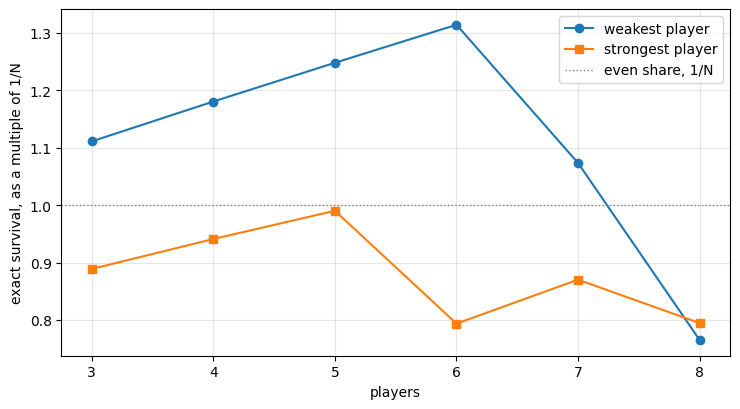

In [10]:
import matplotlib.pyplot as plt

weakest_series = []
strongest_series = []
for n in counts:
    survival = solved[n]["survival"]
    weakest_series.append(survival[0] * n)
    strongest_series.append(survival[-1] * n)

figure, axis = plt.subplots(figsize=(7.5, 4.2))
axis.plot(counts, weakest_series, marker="o", label="weakest player")
axis.plot(counts, strongest_series, marker="s", label="strongest player")
axis.axhline(1.0, color="grey", linestyle=":", linewidth=1, label="even share, 1/N")
axis.set_xlabel("players")
axis.set_ylabel("exact survival, as a multiple of 1/N")
axis.set_xticks(counts)
axis.grid(alpha=0.3)
axis.legend()
figure.tight_layout()
plt.show()

**So a ratio that grows with player count is `shoot_strongest`'s signature, not a sign of good
play.** The equilibrium's advantage to the weakest peaks and then reverses; the heuristic's
climbs without stopping. A success criterion that rewarded a large gap between the weakest
player and the field would therefore reward *resembling the heuristic*, and would score the
actual equilibrium badly at N=7 and N=8.

That is why folder 03 checks the **whole profile** against the exact answer, and separately
measures **who the agent shoots**, rather than treating this ratio as a verdict.

### Is it the tighter field? Tested, not assumed

There is a second thing changing along this axis. The range [0.4, 0.8] is fixed, so more
players means the players are packed more tightly, not just that there are more of them.
A natural guess is that being the weakest matters less when everyone is nearly equally good,
and that this is what makes the advantage reverse.

The solver can test that guess directly, because it can solve games this notebook was never
asked to: the same accuracies packed more or less tightly. Two tests, each changing one thing.

In [11]:
print("  N   accuracy gap between neighbouring ranks, in the standard game")
for n in counts:
    accuracies = accuracy_set(n)
    print(f"  {n}          {accuracies[1] - accuracies[0]:.4f}")


def weakest_advantage(n, gap, middle=0.6):
    """The weakest player's survival as a multiple of 1/N, for N players spaced `gap` apart.

    Returns None when the game has no pure equilibrium, which can happen; that is the same
    wall this notebook hit at N=9.
    """
    lowest = middle - (n - 1) / 2 * gap
    highest = middle + (n - 1) / 2 * gap
    try:
        survival = solve_all(accuracy_set(n, lowest, highest))[0]
    except RuntimeError:
        return None
    return survival[0] * n


def shown(value):
    if value is None:
        return " none"
    return f"{value:5.3f}"

  N   accuracy gap between neighbouring ranks, in the standard game
  3          0.2000
  4          0.1333
  5          0.1000
  6          0.0800
  7          0.0667
  8          0.0571


**Test 1: hold the player count fixed and change only the spacing.** The middle accuracy stays
at 0.6. If a tighter field made being the weakest matter less, the advantage would fall as the
spacing shrinks.

In [12]:
test_one = {
    5: [0.12, 0.10, 0.08, 0.06, 0.03],
    6: [0.10, 0.08, 0.06, 0.04],
    7: [0.08, 0.0667, 0.05, 0.04],
    8: [0.07, 0.0571, 0.045, 0.035],
}
rises_overall = 0
for n in test_one:
    row_cells = []
    advantages = []
    for gap in test_one[n]:
        advantage = weakest_advantage(n, gap)
        advantages.append(advantage)
        row_cells.append(f"gap {gap:.4f}: {shown(advantage)}")
    print(f"  N={n}   " + "   ".join(row_cells))
    if advantages[-1] is not None and advantages[0] is not None and advantages[-1] > advantages[0]:
        rises_overall = rises_overall + 1
print()
print(f"tightest spacing beats loosest at {rises_overall} of {len(test_one)} player counts")

  N=5   gap 0.1200: 1.190   gap 0.1000: 1.248   gap 0.0800: 1.314   gap 0.0600: 1.372   gap 0.0300: 1.444
  N=6   gap 0.1000: 0.897   gap 0.0800: 1.314   gap 0.0600: 1.378   gap 0.0400: 1.431


  N=7   gap 0.0800: 1.042   gap 0.0667: 1.073   gap 0.0500: 1.422   gap 0.0400: 1.447


  N=8   gap 0.0700: 0.819   gap 0.0571: 0.765   gap 0.0450: 1.200   gap 0.0350: 1.478

tightest spacing beats loosest at 4 of 4 player counts


**Test 2: hold the spacing fixed and change only the player count.** If the tighter field were
what causes the reversal, then with the spacing frozen the advantage should stop falling.

In [13]:
test_two = [0.10, 0.08, 0.0571, 0.04]
falls_anyway = 0
for gap in test_two:
    row_cells = []
    advantages = []
    for n in range(3, 9):
        advantage = weakest_advantage(n, gap)
        advantages.append(advantage)
        row_cells.append(f"N={n}: {shown(advantage)}")
    print(f"  gap fixed at {gap:.4f}   " + "  ".join(row_cells))
    solved_advantages = []
    for advantage in advantages:
        if advantage is not None:
            solved_advantages.append(advantage)
    if solved_advantages[-1] < max(solved_advantages):
        falls_anyway = falls_anyway + 1
print()
print(f"the advantage still falls from its peak, with spacing frozen, at {falls_anyway} of "
      f"{len(test_two)} spacings")

  gap fixed at 0.1000   N=3: 1.319  N=4: 1.276  N=5: 1.248  N=6: 0.897  N=7: 1.178  N=8:  none


  gap fixed at 0.0800   N=3: 1.358  N=4: 1.328  N=5: 1.314  N=6: 1.314  N=7: 1.042  N=8:  none


  gap fixed at 0.0571   N=3: 1.400  N=4: 1.383  N=5: 1.380  N=6: 1.387  N=7: 1.107  N=8: 0.765


  gap fixed at 0.0400   N=3: 1.431  N=4: 1.421  N=5: 1.422  N=6: 1.431  N=7: 1.447  N=8: 1.213

the advantage still falls from its peak, with spacing frozen, at 4 of 4 spacings


**What the two tests say, read off the tables above rather than assumed.**

Test 1: with the player count fixed, a tighter field almost always *raises* the weakest
player's advantage. The one exception is at N=8, where going from 0.07 to the standard 0.0571
lowers it slightly before tighter spacings raise it again. So "being the weakest matters less
when everyone is nearly equal" is the wrong way round: tighter packing generally helps the
weakest.

Test 2: with the spacing frozen, the advantage still ends below its peak at every spacing
tested; at the tightest one the fall comes only at N=8. The reversal does not need the
tighter packing to happen.

Together: the tightening that comes with a larger field is **not** what makes the advantage
reverse, and mostly pushes the other way. One honest limit on test 2: freezing the spacing
means a larger field spans a *wider* range of accuracies, so that test changes something too.
What does drive the reversal is not settled here. Note also that some of these games have no
pure equilibrium at all, marked "none", which is the same wall this notebook hit at N=9.

## 4.5 The one state where somebody holds fire

A gruel player may always decline to shoot. In this variant that is a legal move, and the
classical result everyone quotes — that the weakest player should deliberately miss — is about
a *different* variant, the fixed firing order of Kilgour (1975).

So: across every state of every game solved above, where does the equilibrium actually decline
to shoot?

In [14]:
total_states = 0
abstaining_states = []

for n in counts:
    for alive in solved[n]["profiles"]:
        total_states = total_states + 1
        profile = solved[n]["profiles"][alive]
        holds_fire = []
        for shooter in alive:
            if profile[shooter] is ABSTAIN:
                holds_fire.append(shooter)
        if len(holds_fire) > 0:
            abstaining_states.append((n, alive, holds_fire))

print(f"states examined, N={counts[0]} to N={counts[-1]}: {total_states}")
print(f"states where at least one player holds fire: {len(abstaining_states)}")
print()
for n, alive, holds_fire in abstaining_states:
    print(f"  N={n}, state {alive}, holding fire: {holds_fire}")

states examined, N=3 to N=8: 465
states where at least one player holds fire: 1

  N=8, state (0, 1, 2, 3, 4, 5, 6, 7), holding fire: [5, 6]


### It is not the tie-break choosing a quiet equilibrium

Step 3's solver picks the equilibrium with the most shooting when a state has several. If
states routinely had several, "the equilibrium holds fire here" could be an artefact of which
one got picked. So before reading anything into it, check how often that tie-break fired.

In [15]:
states_with_choice = 0
for n in counts:
    for alive in solved[n]["equilibria_counts"]:
        if solved[n]["equilibria_counts"][alive] > 1:
            states_with_choice = states_with_choice + 1

print(f"states with more than one equilibrium, across all {total_states}: "
      f"{states_with_choice}")
print()
if states_with_choice == 0:
    print("The tie-break never fired. Every state in the solvable range has exactly one")
    print("equilibrium, so holding fire was not selected in preference to shooting --")
    print("there was no alternative equilibrium to select against.")
else:
    print("The tie-break did fire, so any abstention finding has to be read alongside")
    print("the possibility that a shooting equilibrium was available and not chosen.")

states with more than one equilibrium, across all 465: 0

The tie-break never fired. Every state in the solvable range has exactly one
equilibrium, so holding fire was not selected in preference to shooting --
there was no alternative equilibrium to select against.


### The state itself

One state, so it can simply be printed in full.

In [16]:
if len(abstaining_states) == 0:
    raise SystemExit("No state holds fire, so the rest of section 4.5 has nothing to "
                     "examine. That is a legitimate outcome if the accuracy range changed; "
                     "it is not the outcome at [0.4, 0.8].")

holding_n, holding_state, holding_players = abstaining_states[0]
accuracies = solved[holding_n]["accuracies"]
profile = solved[holding_n]["profiles"][holding_state]
values_here = solved[holding_n]["all_values"][holding_state]

print(f"N={holding_n}, state {holding_state} -- "
      f"{'the opening state' if len(holding_state) == holding_n else 'a later state'}")
print()
print("   player  accuracy   action        survival")
for shooter in holding_state:
    target = profile[shooter]
    if target is ABSTAIN:
        action = "ABSTAIN"
    else:
        action = f"shoot p{target}"
    print(f"     p{shooter}     {accuracies[shooter]:.4f}    {action:<12}  "
          f"{values_here[shooter]:.5f}")

print()
print("who each player could have shot:")
for shooter in holding_state:
    reachable = neighbours_on_circle(holding_state, shooter)
    print(f"     p{shooter} could shoot {reachable}")

print()
adjacent = False
for shooter in holding_players:
    if set(neighbours_on_circle(holding_state, shooter)) & set(holding_players):
        adjacent = True
print(f"the players holding fire are neighbours of each other: {adjacent}")
ranks = sorted(holding_state, key=lambda p: accuracies[p], reverse=True)
places = []
for shooter in holding_players:
    places.append(ranks.index(shooter) + 1)
print(f"their places by accuracy, strongest first: {sorted(places)} of {len(holding_state)}")

N=8, state (0, 1, 2, 3, 4, 5, 6, 7) -- the opening state

   player  accuracy   action        survival
     p0     0.4000    shoot p7      0.09565
     p1     0.4571    shoot p0      0.15536
     p2     0.5143    shoot p1      0.13454
     p3     0.5714    shoot p2      0.11978
     p4     0.6286    shoot p3      0.13643
     p5     0.6857    ABSTAIN       0.13745
     p6     0.7429    ABSTAIN       0.12147
     p7     0.8000    shoot p0      0.09932

who each player could have shot:
     p0 could shoot [7, 1]
     p1 could shoot [0, 2]
     p2 could shoot [1, 3]
     p3 could shoot [2, 4]
     p4 could shoot [3, 5]
     p5 could shoot [4, 6]
     p6 could shoot [5, 7]
     p7 could shoot [6, 0]

the players holding fire are neighbours of each other: True
their places by accuracy, strongest first: [2, 3] of 8


### By how much does holding fire actually win?

A preference that survives by 1e-9 would be an artefact of floating-point arithmetic. Print
the margin instead of trusting it.

In [17]:
print(f"state {holding_state}, N={holding_n}")
print()
for shooter in holding_players:
    stayed = values_here[shooter]
    print(f"  p{shooter} (accuracy {accuracies[shooter]:.4f}) holds fire, survival {stayed:.6f}")
    for alternative in options_for(holding_state, shooter, "circle"):
        if alternative is ABSTAIN:
            continue
        trial = dict(profile)
        trial[shooter] = alternative
        trial_value = value_of_profile(accuracies, holding_state, trial,
                                       solved[holding_n]["all_values"])[shooter]
        print(f"      shoot p{alternative} (accuracy {accuracies[alternative]:.4f}) instead "
              f"-> {trial_value:.6f}, worse by {stayed - trial_value:.6f}")
    print()

state (0, 1, 2, 3, 4, 5, 6, 7), N=8

  p5 (accuracy 0.6857) holds fire, survival 0.137450
      shoot p4 (accuracy 0.6286) instead -> 0.136512, worse by 0.000938
      shoot p6 (accuracy 0.7429) instead -> 0.136215, worse by 0.001235

  p6 (accuracy 0.7429) holds fire, survival 0.121470
      shoot p5 (accuracy 0.6857) instead -> 0.119285, worse by 0.002186
      shoot p7 (accuracy 0.8000) instead -> 0.117515, worse by 0.003956



### And the weakest player?

This is the question the whole project builds toward, so it is asked over every game solved
rather than just this one state.

In [18]:
print("  N   weakest player's action in the opening state   holds fire anywhere?")
for n in counts:
    opening = tuple(range(n))
    profile_here = solved[n]["profiles"][opening]
    weakest_choice = profile_here[0]
    accuracies_here = solved[n]["accuracies"]

    if weakest_choice is ABSTAIN:
        described = "ABSTAIN"
    else:
        reachable = neighbours_on_circle(opening, 0)
        stronger = reachable[0]
        for candidate in reachable:
            if accuracies_here[candidate] > accuracies_here[stronger]:
                stronger = candidate
        which = "the stronger" if weakest_choice == stronger else "the weaker"
        described = f"shoot p{weakest_choice}, {which} neighbour"

    ever = False
    for alive in solved[n]["profiles"]:
        if 0 in alive and solved[n]["profiles"][alive][0] is ABSTAIN:
            ever = True
    print(f"  {n}   {described:<44}   {ever}")

print()
weakest_stayed = values_here[0]
trial = dict(profile)
trial[0] = ABSTAIN
weakest_if_abstained = value_of_profile(accuracies, holding_state, trial,
                                        solved[holding_n]["all_values"])[0]
print(f"In the one state where others do hold fire (N={holding_n}), the weakest player")
print(f"would lose the most by joining them:")
print(f"  shoots:  {weakest_stayed:.6f}")
print(f"  abstains: {weakest_if_abstained:.6f}")
print(f"  cost of holding fire: {weakest_stayed - weakest_if_abstained:.6f}")

  N   weakest player's action in the opening state   holds fire anywhere?
  3   shoot p2, the stronger neighbour               False
  4   shoot p3, the stronger neighbour               False
  5   shoot p4, the stronger neighbour               False
  6   shoot p5, the stronger neighbour               False
  7   shoot p6, the stronger neighbour               False
  8   shoot p7, the stronger neighbour               False

In the one state where others do hold fire (N=8), the weakest player
would lose the most by joining them:
  shoots:  0.095650
  abstains: 0.087432
  cost of holding fire: 0.008218


So in this variant **holding fire is a tool of the strong**, and only barely, and only once.
The weakest player shoots in every state of every game the solver can reach, and where anyone
does hold fire the weakest is the player with the most to lose by copying them.

The classical "the weakest should miss" is not being contradicted — it is a result about the
**fixed-order** game, where you know your shot is coming and can wait. Here the shooter is
drawn at random, so waiting has no comparable value.

## 4.6 Every exact answer, written out in full

The tables above round to five decimals to stay readable. This cell prints every survival
probability the solver produced, at twelve decimals, one per line, in a fixed format.

Other folders quote these numbers, and folders 03 and 04 type them into their own source
because no folder may import another. These lines are the reference: a quotation anywhere
in the repository can be checked against what this solver actually computed rather than
against a copy.

In [19]:
for n in sorted(solved):
    for rank in range(n):
        value = solved[n]["survival"][rank]
        print(f"exact N={n} rank {rank} survival {value:.12f}")

exact N=3 rank 0 survival 0.370370370370
exact N=3 rank 1 survival 0.333333333333
exact N=3 rank 2 survival 0.296296296296
exact N=4 rank 0 survival 0.295119810745
exact N=4 rank 1 survival 0.252934472934
exact N=4 rank 2 survival 0.216683201058
exact N=4 rank 3 survival 0.235262515263
exact N=5 rank 0 survival 0.249589088015
exact N=5 rank 1 survival 0.210727066546
exact N=5 rank 2 survival 0.179703903149
exact N=5 rank 3 survival 0.161941180686
exact N=5 rank 4 survival 0.198038761604
exact N=6 rank 0 survival 0.219027356078
exact N=6 rank 1 survival 0.185207838231
exact N=6 rank 2 survival 0.160367483098
exact N=6 rank 3 survival 0.170102961952
exact N=6 rank 4 survival 0.133018823818
exact N=6 rank 5 survival 0.132275536822
exact N=7 rank 0 survival 0.153350104240
exact N=7 rank 1 survival 0.173430146138
exact N=7 rank 2 survival 0.149161180731
exact N=7 rank 3 survival 0.137605335033
exact N=7 rank 4 survival 0.129962236945
exact N=7 rank 5 survival 0.132172873721
exact N=7 rank 6

## 4.7 Larger fields fail the same way

Section 4.2 stops at the first player count the solver refuses, nine. That leaves open whether a
larger field might happen to avoid the problem, since a fifteen-player game uses different
accuracies and so passes through different states. Running the same solver on 9, 10 and 15
players answers it. Each run solves states smallest first and stops at the first one with no pure
equilibrium, so a refusal is found quickly even where a full solve would take hours.

In [20]:
for n in [9, 10, 15]:
    started = time.time()
    try:
        solve_all(accuracy_set(n), "circle")
        print(f"  N={n}: solved in {time.time() - started:.1f} seconds")
    except RuntimeError as refusal:
        state_text = str(refusal).split("state ")[1]
        alive_count = state_text.count(",") + 1
        print(f"  N={n}: refused after {time.time() - started:.1f} seconds, at a state with "
              f"{alive_count} players alive, {state_text}")

  N=9: refused after 1.8 seconds, at a state with 8 players alive, (0, 1, 2, 4, 5, 6, 7, 8)


  N=10: refused after 4.4 seconds, at a state with 8 players alive, (0, 1, 2, 3, 4, 5, 7, 9)


  N=15: refused after 185.4 seconds, at a state with 8 players alive, (0, 1, 2, 3, 4, 5, 11, 12)


Every field fails, and every one fails at a state with eight players alive. So with accuracies
spread evenly over 0.4 to 0.8, the boundary is not about nine players in particular: once eight
players remain, a state can have no pure stationary equilibrium, and the solver has to solve every
state with eight alive before it can solve a larger game. With other spacings the first failure can
come earlier; this was not explored systematically.

## What to take from step 4

- The exact method reaches **N=8** and refuses at **N=9**, demonstrated by running it.
- **It refuses because a state has no pure equilibrium**, not because it ran out of time. Every
  pure combination in that state was checked and none is stable. The timings grow by about five
  times per player, which would have made N=9 and N=10 perfectly affordable.
- **That state does have a mixed equilibrium**, in which two players randomise between one shot
  and holding fire. So the limit is on this method, backward induction over pure strategies, not
  on the game. Above N=8 this project has no exact answer on record, and that is what makes
  folder 04 a description rather than a validation.
- Survival of the weakest, as a multiple of an even share, **peaks at N=6 and reverses**. By
  N=8 the weakest player is below an even share and worse off than the strongest.
- Under `shoot_strongest` the same measure **climbs at every step**. So a large or growing gap
  in favour of the weakest is that heuristic's signature and not a mark of good play — which
  is why folder 03 compares whole profiles and measures targeting instead.
- A larger field is also a more tightly packed one, but that is **not** what reverses the
  advantage: at a fixed player count, tighter packing generally *helps* the weakest, and
  with the spacing frozen the advantage still falls.
- Across all 465 states of all six solvable games there is **exactly one** where the
  equilibrium holds fire, and **no state has more than one equilibrium**, so that finding is
  not an artefact of choosing between them.
- **The weakest player never holds fire at any N from 3 to 8**, and in the one state where
  others do, abstaining would cost it more than anyone.

Step 5 stays inside this range and asks the question this notebook took for granted: how do
you know the thing the solver returned is an equilibrium at all, and what does it actually do?